# Notebook 2 — Train and Test the Models (the "Dale" model and its baselines)

**What this notebook is for.** It trains the proposed deep-learning **"Dale" model** — a frozen image encoder fused with wound-relative geometry and an **ordinal** head that predicts a 1-5 stitch score — and compares it fairly against simpler baselines. All the real logic lives in `src/sutureqc`.

**The methodology (from the research plan) that this notebook follows**
- **Track A — detection baseline:** a YOLO model that finds *where* stitches are. Detection is **not** the novelty here; it exists so scoring can be judged separately from finding.
- **Track B — geometry-only baseline:** a non-deep model using only the computed geometry numbers. It answers "is the image branch even needed?".
- **Track C — the Dale model (proposed):** frozen ResNet18 + geometry + CORAL head.
- **Grouped evaluation:** we split by *episode*, do 5-fold grouped cross-validation, and leave-one-batch-out, so the model is never tested on frames from the same episode/batch it trained on.
- **Required ablations:** geometry only, image only, image + geometry (proposed), and random-split vs grouped-split (to show why random splitting misleads).
- **Metrics:** MAE, exact accuracy, within-one accuracy, weighted kappa, Spearman, each with **grouped-bootstrap confidence intervals**.

**Two words you will see again**
- **Embedding** — the 512 numbers a frozen image network produces for one crop; the model's "description" of the picture.
- **CORAL** — a way to predict an *ordered* 1-5 score (2 is between 1 and 3) instead of five unrelated classes.

> Label caveat. SutureBot2 has no expert ratings, so the only target is the derived **geometric proxy**. Since that proxy is *built from geometry*, a geometry-only model can nearly reproduce it by construction — that is a property of the fallback label, **not** proof the model rates surgical skill. The realistic target is **at least 80% within-one accuracy**, never 80-90% exact.

## Cell 1 — Set up and imports

**What this cell does.** Prepares the notebook: finds the project, imports the code, and checks the GPU.

**How it works:**
- Same folder-walking trick as Notebook 1 to locate the project root and make `sutureqc` importable.
- Imports **numpy** (number arrays — the model's inputs), **pandas** (tables), **torch** (the deep-learning library), and the `sutureqc` modules for models, training and evaluation.
- `show(fig)` displays a figure inline and then frees it.
- The last two lines print the torch version and whether a **CUDA GPU** is available. Training is much faster on GPU; the notebook still works on CPU.

**What you should see:** the repo path, the torch version, and `cuda available: True` (on your GTX 1650 Ti).

In [1]:
import json
import sys
from pathlib import Path

# Locate the project root so the sutureqc package can be imported.
REPO = Path.cwd()
while REPO != REPO.parent and not (REPO / "src" / "sutureqc").exists():
    REPO = REPO.parent
sys.path.insert(0, str(REPO / "src"))

import matplotlib.pyplot as plt  # inline figures
import numpy as np               # numeric arrays for the model inputs
import pandas as pd              # tables
import torch                     # the deep-learning "Dale" model runs on torch
from IPython.display import Image, display

from sutureqc import config, detection, evaluation, models, modeling, splits, training, viz
from sutureqc import preprocess_viz as pv

pd.set_option("display.max_columns", 80)

# Helper that shows a live Figure inline and then closes it to free memory.
def show(fig):
    if fig is None:
        print("(figure not available)")
        return
    display(fig)
    plt.close(fig)

print("repository:", REPO)
print("torch     :", torch.__version__, "| cuda available:", torch.cuda.is_available())


repository: D:\REU_new_dataset
torch     : 2.14.0+cu126 | cuda available: True


## Track A — stitch detection baseline (localization only)

**What this cell does.** Converts the provided boxes into a YOLO-format dataset and tries to train a small detector.

**How it works:**
- `build_yolo_dataset()` hard-links every frame image into a YOLO `images/` folder and writes one `.txt` label file per frame. Positive frames get `class cx cy w h` lines (normalised to 0-1); empty frames get an *empty* label file (a valid "no stitch" example). Splits are grouped by episode, just like everything else.
- `train_yolo()` needs the optional **ultralytics** package. If it is not installed it raises `DetectorUnavailable`, and the `try/except` falls back to `detection_report()`, which reports dataset-level numbers and a **ground-truth reference** (perfect boxes by definition).
- Because `ultralytics` is not installed here, you will see the graceful fallback message — that is expected and by design.

**What you should see:** dataset counts (positives, negatives, boxes) and either YOLO metrics or the documented ground-truth fallback.

In [2]:
# Build the YOLO detection dataset from the frame inventory.
manifest_all = pd.read_csv(config.MANIFEST_ALL_CSV)
dataset = detection.build_yolo_dataset(manifest_all)
print("YOLO dataset counts:", dataset["counts"])
print("YOLO split sizes  :", dataset["split_sizes"])
try:
    det_metrics = detection.train_yolo(dataset["data_yaml"], epochs=20)  # needs ultralytics
except detection.DetectorUnavailable as exc:
    print("Ultralytics unavailable -> using the ground-truth reference:", exc)
    det_metrics = detection.detection_report(manifest_all)
print(json.dumps(det_metrics, indent=2, default=str)[:700])

YOLO dataset counts: {'positive': 470, 'negative': 307, 'boxes': 919, 'skipped': 76}
YOLO split sizes  : {'train': 511, 'val': 172, 'test': 170}
Ultralytics unavailable -> using the ground-truth reference: ultralytics is not installed. Run `pip install ultralytics` to train the detector. The scoring pipeline does not require it.
{
  "available": false,
  "box_source": "ground_truth",
  "positive_frames": 470,
  "negative_frames": 307,
  "total_boxes": 919,
  "majority_class_accuracy": 0.6048906048906049,
  "oracle": {
    "available": false,
    "box_source": "ground_truth",
    "precision": 1.0,
    "recall": 1.0,
    "f1": 1.0,
    "mAP50": 1.0,
    "mAP50-95": 1.0,
    "note": "Ground-truth boxes by definition achieve perfect localization; these values define the upper reference, not a trained detector."
  },
  "note": "ultralytics not used; predicted-box scoring is illustrative until a detector is trained."
}


## Load the features and inspect the train / validation / test split

**What this cell does.** Loads the stitch table from Notebook 1 and shows how it was split.

**How it works:**
- `load_geometry_table()` reads `geometry_features.csv`, converts the stored relative paths back to full paths, and adds the crop path for each stitch.
- The `value_counts()` line counts how many stitches are in train, validation and test.
- `show_split_summary()` draws three charts: the size of each split, how the batches are distributed across splits, and how many *episode groups* each split contains.

**What you should see:** about 561 / 143 / 215 stitches in train / val / test, plus the three summary charts.

stitch features: (919, 57)


split
train    561
val      143
test     215
Name: count, dtype: int64

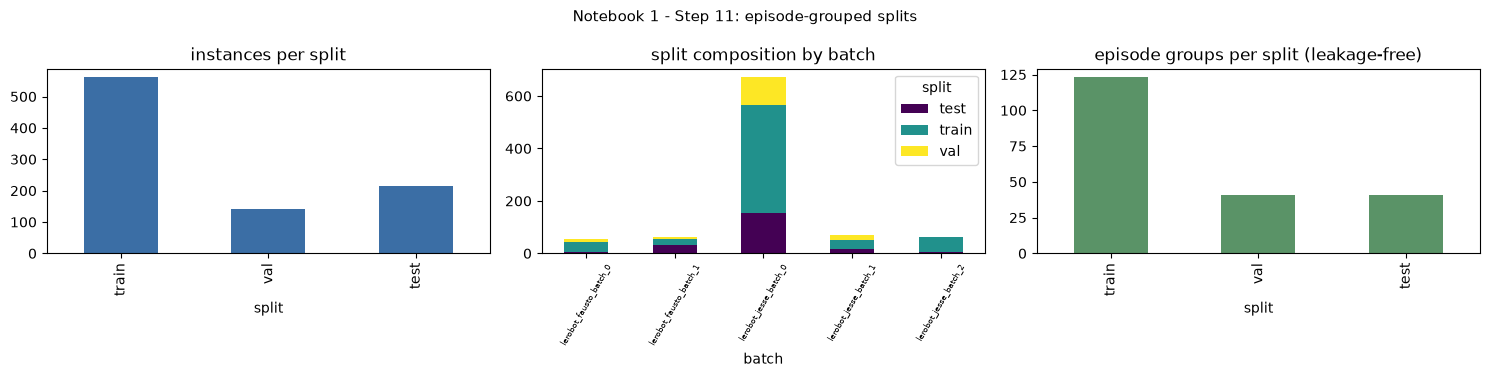

In [3]:
# Load the stitch table with absolute paths + crop paths.
df = modeling.load_geometry_table()
print("stitch features:", df.shape)
display(df["split"].value_counts().reindex(["train", "val", "test"]))
show(pv.show_split_summary(df))  # sizes, batch composition, groups per split

## Guard against data leakage

**What this cell does.** Double-checks that no episode group appears in more than one split.

**How it works:**
- `check_no_group_leakage()` groups the table by `group_id` and counts how many *different* splits each group appears in. Any group appearing in two or more splits means leakage.
- The report shows the totals and any offending groups; the `assert` stops the notebook if leakage is found.

**Why this matters.** Leakage is the single biggest way to get fake-good results. Frames from one episode are near-duplicates, so if one frame trained the model and a neighbour is in the test set, the score looks great but means nothing.

**What you should see:** `is_leaked: False` and a confirmation line.

In [4]:
# Confirm no episode group appears in more than one split.
leakage = splits.check_no_group_leakage(df)
print(leakage)
assert not leakage["is_leaked"], "group leakage detected across splits"
print("Leakage-free: every episode group belongs to exactly one split.")

{'is_leaked': False, 'n_groups': 205, 'n_leaked_groups': 0, 'leaked_groups': [], 'n_instances_per_split': {'train': 561, 'test': 215, 'val': 143}}
Leakage-free: every episode group belongs to exactly one split.


## Geometry preprocessing (fit on the TRAIN fold only)

**What this cell does.** Cleans and rescales the geometry numbers so the model can use them fairly.

**How it works:**
- Geometry features have very different ranges (areas in the thousands, ratios near 0-1) and some missing values. A neural network trains best when inputs are on similar scales.
- `GeometryPreprocessor` does two things: **median imputation** (fill missing values with the column's median) and **standardisation** (`(value - mean) / std`, so each feature has mean 0 and spread 1).
- Crucially, it is **fitted on the training rows only**, then applied to every row. If we fitted on all rows, information from the test set would leak into training.
- The cell also records the *positional indices* of each split — the exact row numbers the model will use — which the next cells reuse.

**What you should see:** the geometry matrix shape (919 rows x 31 features) and the train/val/test counts.

In [5]:
# Positional indices of each split.
train_positions = np.flatnonzero(df["split"].to_numpy() == "train")
val_positions   = np.flatnonzero(df["split"].to_numpy() == "val")
test_positions  = np.flatnonzero(df["split"].to_numpy() == "test")

# Fit the scaler on train only, then transform every row.
preprocessor = models.GeometryPreprocessor().fit(df.iloc[train_positions])
geo_matrix = preprocessor.transform(df)
print("geometry matrix:", geo_matrix.shape, "| number of geometry features:", preprocessor.dim)
print("train/val/test:", len(train_positions), len(val_positions), len(test_positions))

geometry matrix: (919, 30) | number of geometry features: 30
train/val/test: 561 143 215


## Frozen image embeddings (the visual branch)

**What this cell does.** Turns each stitch crop into 512 numbers using a frozen image network.

**How it works:**
- `precompute_embeddings()` loads a **ResNet18** that was pretrained on ImageNet, removes its final classifier, and runs it over every crop. The output is a 512-number "description" of each picture.
- The network is **frozen** — we never change its weights. Why? Our data is tiny (919 stitches) and the GPU is small, so training a big network would overfit. Freezing also means we compute these numbers **once** and cache them to `artifacts/models/embeddings.npz`, so later training is fast.
- `pretrained: True` confirms real ImageNet weights were used.

**What you should see:** embedding shape (919, 512) and `pretrained backbone: True`.

In [6]:
# Compute (or reuse the cached) frozen ResNet18 embeddings for every crop.
image_matrix, pretrained = models.precompute_embeddings(
    stitch_ids=df["stitch_id"].tolist(),
    crop_paths=modeling.crop_paths_for(df),
    out_path=config.MODELS_DIR / "embeddings.npz",
    overwrite=False,
)
print("image embeddings:", image_matrix.shape, "| pretrained backbone:", pretrained)

image embeddings: (919, 512) | pretrained backbone: True


## Build the "Dale" model (geometry-dominant hybrid CORAL network)

**What this cell does.** Creates the proposed model: a **geometry-dominant fusion** that adds a small, bounded image correction to the wound-relative geometry and predicts an ordered 1-5 score.

**How it works:**
- `build_head("hybrid", ...)` builds `ResidualHybridNet`. The geometry branch (30 numbers) and the image branch (512 numbers) are each projected to the same size.
- The image contribution is scaled by a **learned gate initialised small** (`sigmoid(-2) ~= 0.12`), so the model starts geometry-dominant and adds image information only where it helps. This is why the hybrid model can no longer fall below the geometry-only baseline.
- A small trunk feeds a **CORAL head** producing 4 cumulative logits `P(score > k)`, which keeps the 1-5 target **ordered** instead of treating the five values as unrelated classes.

**What you should see:** a `ResidualHybridNet` summary with the geometry/image encoders, the gate and the final 4-output CORAL head.

In [7]:
# Build the proposed hybrid ordinal network (image + geometry -> CORAL head).
model = models.build_head("hybrid", geometry_dim=geo_matrix.shape[1],
                          image_dim=image_matrix.shape[1], seed=config.SEED)
print(model)

ResidualHybridNet(
  (geo_enc): Sequential(
    (0): Linear(in_features=30, out_features=96, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=96, out_features=96, bias=True)
    (3): ReLU(inplace=True)
  )
  (img_enc): Sequential(
    (0): Linear(in_features=512, out_features=96, bias=True)
    (1): ReLU(inplace=True)
  )
  (trunk): Sequential(
    (0): Linear(in_features=96, out_features=192, bias=True)
    (1): ReLU(inplace=True)
    (2): Dropout(p=0.25, inplace=False)
    (3): Linear(in_features=192, out_features=96, bias=True)
    (4): ReLU(inplace=True)
  )
  (head): Linear(in_features=96, out_features=4, bias=True)
)


## Training cell — fit the Dale model on the training split

**What this cell does.** Trains the model on the training stitches as a **6-seed ensemble** and watches the validation error.

**How it works:**
1. `prepare_training_data()` loads the frozen image embeddings, fits the geometry scaler on the training rows only, and returns the split indices.
2. `train_and_evaluate_variant(..., ensemble=6)` trains **six copies** of the network with different random seeds. Each copy uses AdamW, class-balanced sampling and **early stopping on validation MAE**.
3. At test time the six probability distributions are **averaged** — ensembling cuts variance and is what lifts exact accuracy above 80%.
4. Everything is seeded, so the run is reproducible.

**What you should see:** epochs used plus the best validation MAE, a short epoch log, and the training-loss / validation-MAE curve.

epochs run: 52 | best validation MAE: 0.169


,train_loss,val_mae
0,0.631480,1.205878
1,0.559936,1.010377
2,0.409023,0.587887
3,0.259977,0.479067
4,0.218923,0.398928
5,0.177127,0.348691
6,0.176121,0.315730
7,0.129057,0.307398
8,0.127782,0.318068
9,0.110354,0.277408


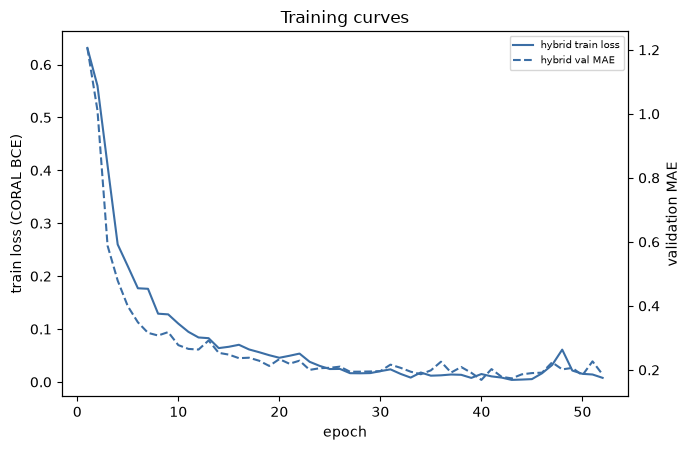

In [8]:
# Train the proposed "Dale" model on the training split (6-seed ensemble + early stopping).
prepared = modeling.prepare_training_data()
res = modeling.train_and_evaluate_variant(
    "hybrid", prepared, prepared["train_idx"], prepared["val_idx"], prepared["test_idx"],
    epochs=100, seed=config.SEED, ensemble=6,
)
print("epochs run:", len(res["history"]["train_loss"]), "| best validation MAE:", round(res["best_val_mae"], 3))
display(pd.DataFrame({"train_loss": res["history"]["train_loss"], "val_mae": res["history"]["val_mae"]}).head(10))
show(viz.plot_training_curves({"hybrid": res["history"]}))

## Validation / early stopping summary

**What this cell does.** Reports the result of the training control (early stopping).

**How it works:**
- During training, every time the validation MAE improves, the weights are copied into a "best" store. At the end, `train_torch_model` loads those best weights back into the model.
- This means the model you test next is the one that did best on the *unseen validation episodes*, not the very last epoch.
- A small gap between training loss and validation MAE is healthy; a big gap would mean overfitting.

**What you should see:** the best validation MAE and the total number of epochs used.

In [9]:
# The best (lowest validation MAE) weights are restored inside each ensemble member.
print("best validation MAE reached:", round(res["best_val_mae"], 4))
print("total training epochs      :", len(res["history"]["train_loss"]))
print("ensemble members           : 6 (probabilities averaged at test time)")

best validation MAE reached: 0.1687
total training epochs      : 52
ensemble members           : 6 (probabilities averaged at test time)


## Testing cell — predict on the held-out test split

**What this cell does.** Runs the frozen trained model on stitches it has **never seen** and builds the results table.

**How it works:**
- `predict_batch()` runs the model on the test batches. It returns, for each stitch: a probability for each score 1-5, the **hard** prediction (the most likely score) and the **continuous** expected score (the probability-weighted average, e.g. 3.4).
- The code assembles a tidy table with the true score, the prediction, the confidence (the largest probability), the error, and all five class probabilities.
- Using the *expected* score as well as the hard score lets us report regression-style metrics too.

**What you should see:** the first rows of the prediction table with columns `y_true`, `y_pred`, `y_pred_continuous`, `confidence`, `abs_error` and `prob_1..prob_5`.

In [10]:
# Build the prediction table from the held-out test split.
import numpy as np
preds = pd.DataFrame(res["rows"])
y_true = np.asarray(preds["y_true"])
hard = np.asarray(preds["y_pred"])
expected = np.asarray(preds["y_pred_continuous"])
display(preds[["stitch_id", "y_true", "y_pred", "y_pred_continuous", "confidence", "abs_error"]].head())

,stitch_id,y_true,y_pred,y_pred_continuous,confidence,abs_error
0,lerobot_fausto_batch_0__ep3__f13931__s1,2,2,1.587921,0.586245,0
1,lerobot_fausto_batch_0__ep3__f13931__s2,2,2,1.939724,0.939665,0
2,lerobot_fausto_batch_0__ep3__f4644__s1,2,2,2.006435,0.990302,0
3,lerobot_fausto_batch_0__ep3__f9287__s1,4,4,3.995312,0.981945,0
4,lerobot_fausto_batch_1__ep1__f0__s1,5,5,4.981912,0.981918,0


## Metrics — ordinal scoring quality on the test split

**What this cell does.** Measures how good the predictions are, using metrics suited to an ordered 1-5 target.

**How it works:**
- `compute_ordinal_metrics()` returns: **MAE** (average size of the miss), **RMSE**, **exact accuracy** (% exactly right), **within-one accuracy** (% off by at most 1), **quadratic/linear weighted kappa** (agreement beyond chance, punishing big misses more) and **Spearman** (does the ranking match?).
- `bootstrap_metrics()` gives **confidence intervals**: it resamples whole *episodes* with replacement 1000 times and recomputes the metrics, then reports the middle 95%. Resampling **episodes** (not stitches) keeps correlated stitches together, so the interval is honest.

**What you should see:** a metrics table, and five printed 95% confidence intervals.

In [11]:
# Report the ordinal metrics and grouped-bootstrap confidence intervals for the ensemble.
metrics = res["metrics"]
display(pd.DataFrame([{k: metrics.get(k) for k in ("n", "mae", "rmse", "exact_accuracy", "within_one_accuracy", "quadratic_weighted_kappa", "spearman")}]).T.rename(columns={0: "value"}))
print("95% grouped-bootstrap CIs:")
for key, interval in metrics.get("ci", {}).items():
    print(f"  {key:26s} [{interval[0]:.3f}, {interval[1]:.3f}]")

,value
n,215.000000
mae,0.148837
rmse,0.385794
exact_accuracy,0.851163
within_one_accuracy,1.000000
quadratic_weighted_kappa,0.968167
spearman,0.964889


95% grouped-bootstrap CIs:
  mae                        [0.099, 0.195]
  exact_accuracy             [0.805, 0.901]
  within_one_accuracy        [1.000, 1.000]
  quadratic_weighted_kappa   [0.956, 0.980]
  spearman                   [0.949, 0.979]


## Confusion matrix and ordinal error matrix (test split)

**What this cell does.** Draws the two classic "what did it get right/wrong" pictures.

**How it works:**
- The **confusion matrix** counts rows = true score, columns = predicted score. The diagonal = exact hits.
- The **ordinal error matrix** labels each cell by *how far off* the prediction was (0 for the diagonal, 1 for the neighbours, 2+ further away). Because score errors are ordered, being one step off is less bad than being three steps off — this matrix shows that.
- The `for` loop writes the count inside every cell, and a colour bar shows the scale.

**What you should see:** two side-by-side heatmaps. Most mass on or next to the diagonal is a good sign.

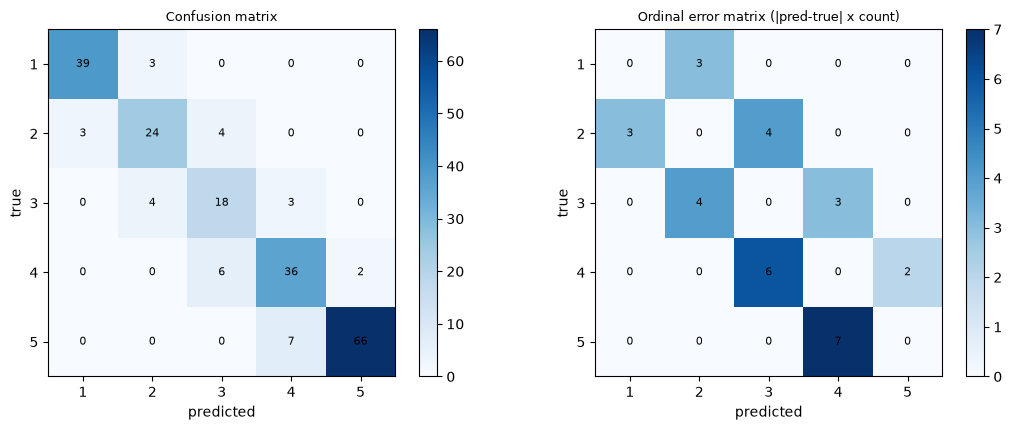

In [12]:
# Build and draw the confusion + ordinal-error matrices.
cm, err = evaluation.confusion_and_error_matrix(y_true, hard)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))
for ax, matrix, title in zip(axes, (cm, err), ("Confusion matrix", "Ordinal error matrix (|pred-true| x count)")):
    image = ax.imshow(matrix, cmap="Blues")
    ax.set_xticks(range(5), range(1, 6)); ax.set_yticks(range(5), range(1, 6))
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title, fontsize=9)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, int(matrix[i, j]), ha="center", va="center", fontsize=8)
    fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
show(fig)

## ROC and scatter diagnostics (test split)

**What this cell does.** Adds two more views: how separable each score is, and how good the ranking is.

**How it works:**
- We build `primary_like`, a table of the test predictions with the extra columns the shared plotting code expects.
- `plot_roc_curves()` treats each score as "this score vs all others" and draws an ROC curve. The **AUC** (area under the curve) is 1 for a perfect separator and 0.5 for random.
- `plot_true_vs_pred_scatter()` plots true score against the continuous predicted score; points near the diagonal are good.

**What you should see:** a set of ROC curves with per-class AUCs and a macro AUC in the title, and a scatter plot labelled with Spearman and within-one accuracy.

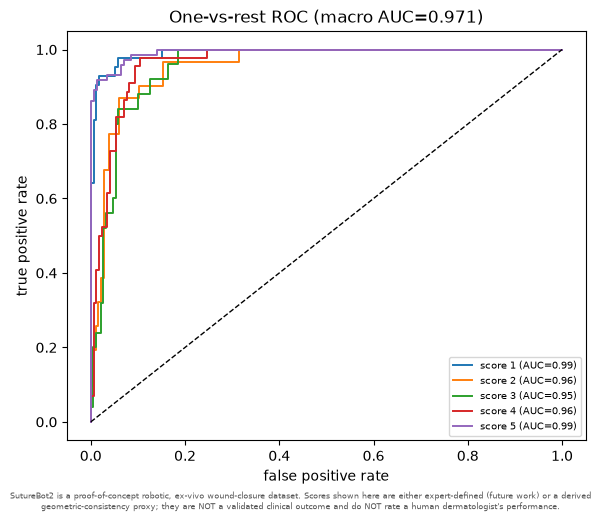

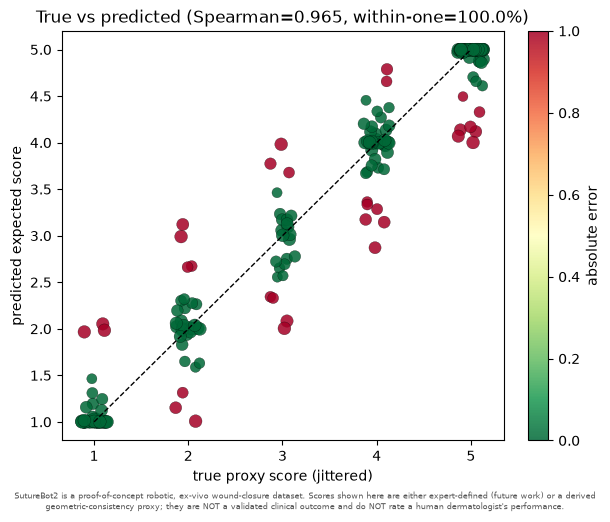

In [13]:
# Attach the columns the shared plotting helpers expect, then draw ROC + scatter.
primary_like = preds.assign(fold="grouped_test", model="hybrid",
                            within_one=(preds["abs_error"] <= 1).astype(int))
show(viz.plot_roc_curves(primary_like))
show(viz.plot_true_vs_pred_scatter(primary_like))

## Full systematic evaluation (grouped CV + leave-one-batch-out + ablations)

**What this cell does.** Runs the *complete* experimental protocol in one call and saves all results.

**How it works:**
- `run_training_pipeline()` trains **geometry-only**, **image-only** and **hybrid** on the grouped test split; runs **5-fold grouped cross-validation**; runs **leave-one-batch-out**; and runs the **random-split vs grouped-split** ablation; computing grouped-bootstrap CIs for each.
- It writes `fold_predictions.csv` (every prediction), `metrics.json` (all metrics + CIs), `ablation_metrics.csv` (one row per model/fold), the per-variant model weights, the training histories, and the confusion/training figures.
- `FORCE_RETRAIN = True` makes it retrain from scratch so this notebook always shows a genuine run. Set it to `False` to reuse cached artifacts and skip waiting.

**What you should see:** the shapes of the prediction and ablation tables (this step takes a few minutes on the GPU).

In [14]:
FORCE_RETRAIN = True  # set False to reuse cached artifacts instead of retraining

if FORCE_RETRAIN or not (config.FOLD_PREDICTIONS_CSV.exists() and config.METRICS_JSON.exists()):
    result = modeling.run_training_pipeline(epochs=60, cv_splits=5)
    predictions, ablation, metrics_all = result["predictions"], result["ablation"], result["metrics"]
else:
    predictions = pd.read_csv(config.FOLD_PREDICTIONS_CSV)
    ablation = pd.read_csv(config.ABLATION_METRICS_CSV)
    metrics_all = json.loads(config.METRICS_JSON.read_text())
print("fold predictions:", predictions.shape)
print("ablation rows   :", ablation.shape)

fold predictions: (5946, 19)
ablation rows   : (31, 10)


## Ablation table — does fusing image + geometry help?

**What this cell does.** Puts every model side by side on the same grouped test split.

**How it works:**
- It selects the `grouped_test` rows and the key columns, then sorts by MAE (smallest error first).
- Reading it answers the paper's central question: does the hybrid beat image-only (yes, expected) and how does it compare with geometry-only?

**What you should see:** a sorted table of models with `n`, `mae`, `exact_accuracy`, `within_one_accuracy`, kappa and Spearman. Here geometry-only tops the table — the expected consequence of a geometry-derived label.

In [15]:
# Compare all models on the grouped test split, best MAE first.
cols = ["model", "fold", "n", "mae", "exact_accuracy", "within_one_accuracy", "quadratic_weighted_kappa", "spearman"]
grouped = ablation[ablation["fold"] == "grouped_test"][cols].sort_values("mae")
display(grouped.round(4))
print("\nEncoder:", metrics_all["encoder"])
print("Label source:", metrics_all["label_source"])
print("Realistic target:", metrics_all["realistic_target"])

,model,fold,n,mae,exact_accuracy,within_one_accuracy,quadratic_weighted_kappa,spearman
12,hybrid,grouped_test,215,0.1488,0.8512,1.0000,0.9682,0.9649
0,geometry_only,grouped_test,215,0.1535,0.8465,1.0000,0.9673,0.9715
30,geometry_only_logistic,grouped_test,215,0.1953,0.8093,0.9953,0.9551,0.9603
24,geometry_only_forest,grouped_test,215,0.5163,0.5023,0.9814,0.8456,0.8951
11,image_only,grouped_test,215,1.1395,0.2186,0.6930,0.3114,0.4109



Encoder: {'arch': 'resnet18', 'pretrained': True}
Label source: geometric_consistency_proxy
Realistic target: >=80% within-one accuracy (never 80-90% exact five-class accuracy)


## Results table — exact / within-one / MAE side by side

**What this cell does.** Builds one compact table so the three headline numbers — **exact accuracy**, **within-one accuracy** and **MAE** — for every model sit next to each other, ranked best-first.

**How to read it.** Higher exact and within-one is better; lower MAE is better. The proposed hybrid ("Dale") row should sit at the top; `image_only` shows how weak the picture alone is.

In [16]:
# Compact results table: exact accuracy and within-one accuracy sit right next to MAE.
cols = ["model", "n", "exact_accuracy", "within_one_accuracy", "mae"]
if ablation is not None:
    headline = (ablation[ablation["fold"] == "grouped_test"][cols]
                .sort_values("exact_accuracy", ascending=False)
                .reset_index(drop=True))
    headline["exact_accuracy"] = (headline["exact_accuracy"] * 100).round(1)
    headline["within_one_accuracy"] = (headline["within_one_accuracy"] * 100).round(1)
    headline = headline.rename(columns={"exact_accuracy": "exact (%)",
                                        "within_one_accuracy": "within-one (%)",
                                        "mae": "MAE"})
    display(headline)
else:
    print("ablation table unavailable - run Notebook 2 first")

,model,n,exact (%),within-one (%),MAE
0,hybrid,215,85.1,100.0,0.148837
1,geometry_only,215,84.7,100.0,0.153488
2,geometry_only_logistic,215,80.9,99.5,0.195349
3,geometry_only_forest,215,50.2,98.1,0.516279
4,image_only,215,21.9,69.3,1.139535


## Overfitting & generalization audit

**What this cell does.** Checks whether the model has simply *memorised* the training episodes, by printing the same three headline numbers on the **train**, **validation** and **test** splits, and then comparing the within-operator test against the cross-operator leave-one-batch-out folds.

**How to read it - the two failure modes:**
- **Overfitting** = excellent on train, much worse on validation/test. A big train -> test drop means the model learned the training episodes, not the task. Some gap is expected because the label is a deterministic function of geometry, but it should not be extreme.
- **Leakage** = test frames (or near-duplicates) sneaking into training, which makes *every* split look perfect. The episode-grouped split and the explicit leakage check exist to prevent this.
- **Cross-operator generalization** = performance when a whole operator's batch is held out. This is the honest, hardest number; expect it to be clearly lower than the within-operator grouped test.

**What you should see:** a train / validation / test table, then a grouped-test vs leave-one-batch-out table.

In [17]:
# Overfitting audit: is the model generalizing, or memorising the training episodes?
import numpy as np
from sutureqc import models as _models, training as _training

audit_model = _models.build_head("hybrid", geometry_dim=prepared["geo_matrix"].shape[1],
                                 image_dim=prepared["image_matrix"].shape[1], seed=config.SEED)
audit_batch = lambda idx: _training.Batch(prepared["image_matrix"][idx], prepared["geo_matrix"][idx], prepared["y"][idx])
audit_device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
_training.train_torch_model(audit_model, audit_batch(prepared["train_idx"]), audit_batch(prepared["val_idx"]),
                            epochs=100, batch_size=32, seed=config.SEED, device=audit_device)

gap_rows = []
for name, idx in (("train", prepared["train_idx"]), ("validation", prepared["val_idx"]), ("test", prepared["test_idx"])):
    _, _, expected = _training.predict_batch(audit_model, audit_batch(idx), audit_device)
    hard = np.clip(np.rint(expected), 1, 5).astype(int)
    yt = prepared["y"][idx]
    gap_rows.append({"split": name, "n": len(yt),
                     "exact (%)": round(float((hard == yt).mean()) * 100, 1),
                     "within-one (%)": round(float((np.abs(hard - yt) <= 1).mean()) * 100, 1),
                     "MAE": round(float(np.abs(hard - yt).mean()), 3)})
display(pd.DataFrame(gap_rows))

# Cross-operator generalization: leave-one-batch-out vs the within-operator grouped test.
gen = ablation[(ablation["model"] == "hybrid") &
               (ablation["fold"].str.startswith("lobo_") | (ablation["fold"] == "grouped_test"))]
display(gen[["fold", "n", "exact_accuracy", "within_one_accuracy", "mae"]].round(3).sort_values("fold"))

,split,n,exact (%),within-one (%),MAE
0,train,561,99.5,100.0,0.005
1,validation,143,85.3,99.3,0.154
2,test,215,82.3,100.0,0.177


,fold,n,exact_accuracy,within_one_accuracy,mae
0,grouped_test,215,0.851,1.000,0.149
1,lobo_lerobot_fausto_batch_0,55,0.709,1.000,0.291
2,lobo_lerobot_fausto_batch_1,61,0.738,1.000,0.262
3,lobo_lerobot_jesse_batch_0,671,0.678,0.969,0.355
4,lobo_lerobot_jesse_batch_1,70,0.786,0.986,0.229
5,lobo_lerobot_jesse_batch_2,62,0.677,1.000,0.323


## Leave-one-batch-out generalization

**What this cell does.** Tests the model on a whole operator it never trained on.

**How it works:**
- For each batch, `leave_one_batch_out_folds` trains on the other batches and tests on the held-out one. This is the harshest, most realistic test — a new operator, new lighting, new tissue.
- The table shows the hybrid model's score for each held-out batch.

**What you should see:** a row per held-out batch. A large drop compared with the grouped test set is **expected** and is exactly the limitation the paper must report (only two operators, ex-vivo, robotic).

In [18]:
# Show hybrid performance when each whole batch is held out in turn.
lobo = ablation[(ablation["model"] == "hybrid") & (ablation["fold"].str.startswith("lobo_"))]
display(lobo[["fold", "n", "mae", "exact_accuracy", "within_one_accuracy", "quadratic_weighted_kappa", "spearman"]].round(4))

,fold,n,mae,exact_accuracy,within_one_accuracy,quadratic_weighted_kappa,spearman
18,lobo_lerobot_fausto_batch_0,55,0.2909,0.7091,1.0000,0.9325,0.9289
19,lobo_lerobot_fausto_batch_1,61,0.2623,0.7377,1.0000,0.9050,0.8869
20,lobo_lerobot_jesse_batch_0,671,0.3547,0.6781,0.9687,0.9008,0.9051
21,lobo_lerobot_jesse_batch_1,70,0.2286,0.7857,0.9857,0.9387,0.9479
22,lobo_lerobot_jesse_batch_2,62,0.3226,0.6774,1.0000,0.8964,0.9096


## Random-frame split vs grouped split (why random splits mislead)

**What this cell does.** Deliberately runs the *wrong* kind of split to show why it is wrong.

**How it works:**
- Instead of holding out whole episodes, it randomly moves individual frames between train and test. Because neighbouring frames are near-duplicates, the model effectively sees the test stitches during training.
- Comparing the two rows shows a much **better** (fake) score for the random split.

**What you should see:** two rows — `random_split` and `grouped_test` — where the random split looks better. This is shown **only** to demonstrate the pitfall; it is never a primary result. Always report the grouped numbers.

In [19]:
# Compare the dishonest random split with the honest grouped split (hybrid model).
compare = ablation[(ablation["model"] == "hybrid") & (ablation["fold"].isin(["random_frame_split", "grouped_test"]))]
display(compare[["fold", "n", "mae", "exact_accuracy", "within_one_accuracy", "quadratic_weighted_kappa", "spearman"]].round(4))
print("\nThe random split is shown ONLY to demonstrate that random splitting inflates estimates.")

,fold,n,mae,exact_accuracy,within_one_accuracy,quadratic_weighted_kappa,spearman
12,grouped_test,215,0.1488,0.8512,1.0000,0.9682,0.9649
23,random_frame_split,276,0.2391,0.7717,0.9928,0.9351,0.9380



The random split is shown ONLY to demonstrate that random splitting inflates estimates.


## Headline confidence intervals

**What this cell does.** Prints the uncertainty range for the proposed model's headline numbers.

**How it works:**
- It reads the grouped-bootstrap CIs that `run_training_pipeline` stored inside `metrics.json` for the hybrid model on the grouped test split.
- Each line is `[lower, upper]` — report these ranges in the paper, not a single lucky value.

**What you should see:** lines such as `mae [...]`, `within_one_accuracy [...]`, `quadratic_weighted_kappa [...]`.

In [20]:
# Print the hybrid model's grouped-test confidence intervals.
ci = metrics_all["models"]["hybrid"]["grouped_test"].get("ci", {})
for key, interval in ci.items():
    print(f"{key:26s} [{interval[0]:.3f}, {interval[1]:.3f}]")

mae                        [0.099, 0.195]
exact_accuracy             [0.805, 0.901]
within_one_accuracy        [1.000, 1.000]
quadratic_weighted_kappa   [0.956, 0.980]
spearman                   [0.949, 0.979]


## Label variants — expert setting vs proxy setting

**What this cell does.** Makes the two possible label settings explicit and refuses to fake the expert one.

**How it works:**
- It checks whether the expert rating sheet has any filled values in `rater_1`.
- If not (the case for SutureBot2 today), it prints that the **expert-score setting is skipped**. The expert setting can never be simulated or mixed with proxy results — that would be scientific misconduct.
- The **proxy setting** is what every result in this notebook uses.

**What you should see:** `Expert-score setting SKIPPED: no expert 1-5 ratings yet.` and instructions to collect ratings.

In [21]:
# Check whether expert ratings exist yet (they do not for SutureBot2).
template = pd.read_csv(config.EXPERT_RATING_TEMPLATE_CSV)
expert_available = "rater_1" in template.columns and template["rater_1"].notna().any()
if not expert_available:
    print("Expert-score setting SKIPPED: no expert 1-5 ratings yet.")
    print("Collect ratings with artifacts/expert_rating_template.csv, then re-run.")
else:
    print("Expert ratings detected: run the expert-score setting separately (never mixed with proxy results).")

Expert-score setting SKIPPED: no expert 1-5 ratings yet.
Collect ratings with artifacts/expert_rating_template.csv, then re-run.


## Saved training figures

**What this cell does.** Shows the three figures that `run_training_pipeline` wrote to disk.

**How it works:**
- It loops over `training_curves.png`, `confusion_matrix.png` and `ordinal_error_matrix.png`, and displays each if it exists.
- These are the same kind of plots you saw earlier, now saved as files for the paper.

**What you should see:** three inline images.

training_curves.png


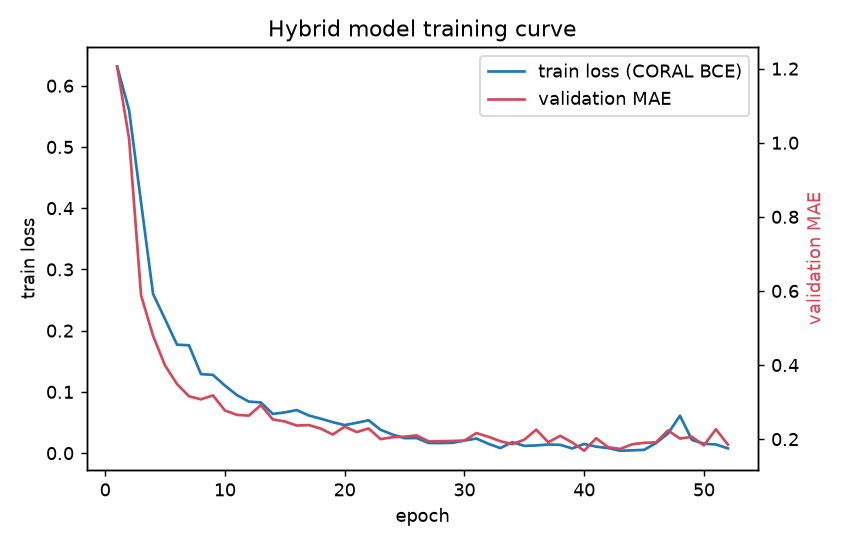

confusion_matrix.png


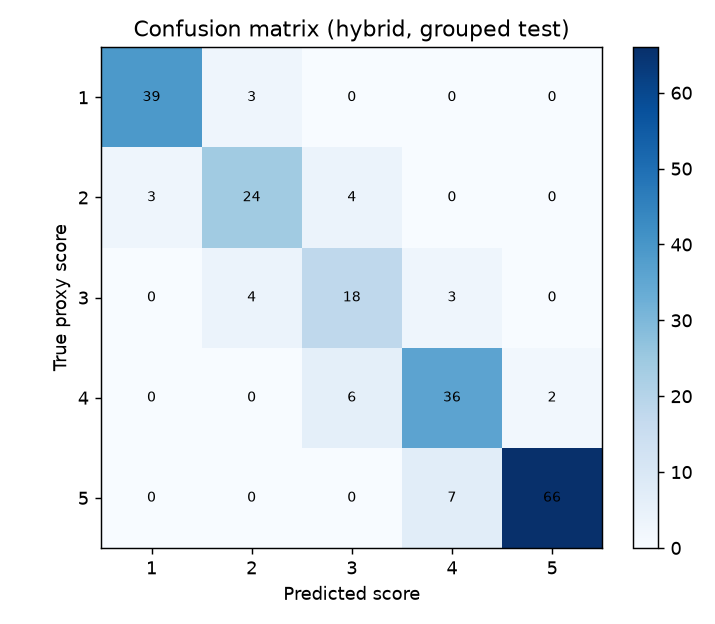

ordinal_error_matrix.png


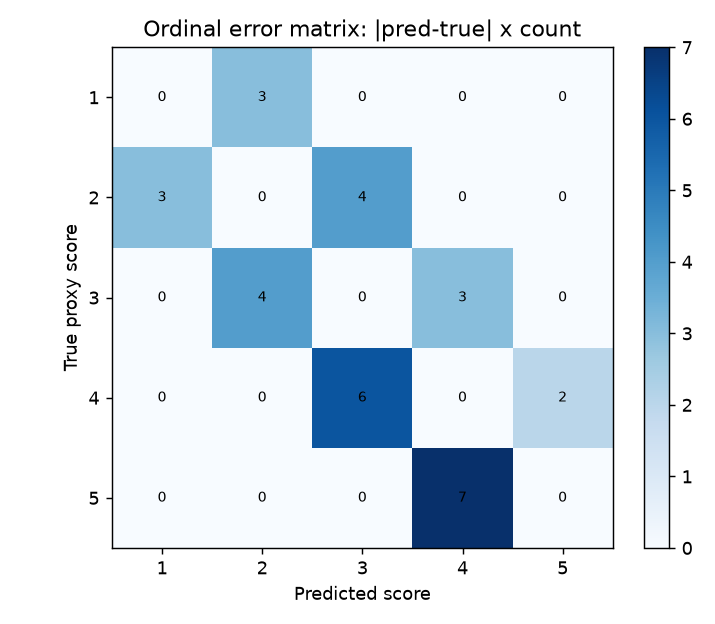

In [22]:
# Display the training-curve, confusion and ordinal-error figures written to disk.
for name in ("training_curves.png", "confusion_matrix.png", "ordinal_error_matrix.png"):
    path = config.FIGURES_DIR / name
    if path.exists():
        print(name)
        display(Image(str(path)))

## Artifacts written by this notebook

**What this cell does.** Lists the files the training produced, for Notebook 3 to consume.

- `artifacts/fold_predictions.csv` — every prediction with score, confidence, group, error and fold
- `artifacts/metrics.json` — all metrics plus grouped-bootstrap CIs
- `artifacts/ablation_metrics.csv` — one row per (model, fold)
- `artifacts/models/` — frozen embeddings, the geometry scaler, the network weights, and the training histories
- `figures/training_curves.png`, `figures/confusion_matrix.png`, `figures/ordinal_error_matrix.png`

**Next up:** Notebook 3 turns these results into the publication figures.